In [1]:
import random
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

SEED = 42
SEQ_LEN = 14
UMBRAL_DECISION = 0.5

In [2]:
FEATURES = ["rango_intradia", "ret_1d", "ret_5d", "ret_10d",
            "dist_sma_7", "dist_sma_21", "vol_7d", "vol_21d", "diff_sma_7_21"]

Se importan las librerias , sobretodo "yfinance" que es una libreria de codigo abierto que nos sirve para descargar datos financieros y de mercado desde Yahoo Finance de forma automatica y gratitua

### Preparacion de datos y descarga de los mismos


In [3]:
def preparar_datos_usdcop(ticker="USDCOP=X", periodo="3y", umbral_venta=-0.003,
                          excluir_vela_parcial=True):
    # 1) Descarga
    data_raw = yf.Ticker(ticker).history(period=periodo)
    if data_raw.empty:
        raise ValueError("No se descargaron datos: revisa conexión o ticker.")

    # 2) Limpieza
    df = data_raw[["High", "Low", "Close"]].copy()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df = df.sort_index()
    df = df[~df.index.duplicated(keep="last")]
    df = df.dropna(subset=["Close"])
    df = df[df["Close"] > 0]

    # Excluir la vela del día en curso (aún incompleta)
    if excluir_vela_parcial:
        hoy_utc = pd.Timestamp.now(tz="UTC").tz_localize(None).normalize()
        df = df[df.index < hoy_utc]

    # Coherencia OHLC: High >= Close >= Low
    df["High"] = df[["High", "Close"]].max(axis=1)
    df["Low"] = df[["Low", "Close"]].min(axis=1)

    # 3) Variables causales (solo información de hoy hacia atrás)
    df["rango_intradia"] = (df["High"] - df["Low"]) / df["Close"]
    df["ret_1d"] = df["Close"].pct_change(1)
    df["ret_5d"] = df["Close"].pct_change(5)
    df["ret_10d"] = df["Close"].pct_change(10)

    sma_7 = df["Close"].rolling(7).mean()
    sma_21 = df["Close"].rolling(21).mean()
    df["dist_sma_7"] = (df["Close"] - sma_7) / sma_7
    df["dist_sma_21"] = (df["Close"] - sma_21) / sma_21
    df["diff_sma_7_21"] = (sma_7 - sma_21) / sma_21

    df["vol_7d"] = df["ret_1d"].rolling(7).std()
    df["vol_21d"] = df["ret_1d"].rolling(21).std()

    # 4) Target: ¿mañana cae al menos |umbral| respecto a hoy?
    retorno_manana = df["Close"].shift(-1) / df["Close"] - 1
    df["target_venta"] = np.where(retorno_manana.isna(), np.nan,
                                  (retorno_manana <= umbral_venta).astype(float))

    # 5) Salidas
    ultima_fila = df.dropna(subset=FEATURES).iloc[[-1]][["Close"] + FEATURES]

    df_train = df.dropna(subset=FEATURES + ["target_venta"])[FEATURES + ["target_venta"]].copy()
    df_train["target_venta"] = df_train["target_venta"].astype(int)

    return df_train, ultima_fila, FEATURES

## Limpieza basica en memoria


# En el contexto de trading y finanzas (o al usar librerías como yfinance), «intradía» significa dentro del mismo día de negociación (es decir, movimientos de precios en intervalos menores a un día, como 1, 5, 15 o 60 minutos).
Por su parte, «intradía inválida» suele referirse a un error técnico al pedir esos datos o a una regla de mercado que se rompe

## Feature engineering estrictamente causal (solo información de hoy y días anteriores)

## Variable objetivo (target) para el siguiente cierre (t+1)

## Separar datos listos para entrenar/evaluar vs. última fila para predecir el próximo día

In [4]:
df_train, ultima_fila, cols_x = preparar_datos_usdcop()

print(f"Filas listas para entrenar/validar: {len(df_train)}")
print(f"Proporción de clase positiva: {df_train['target_venta'].mean():.2%}")
print("\nÚltima fila (para predecir el siguiente día):")
print(ultima_fila.round(5).to_string())

df_train.to_csv("usdcop_train.csv")   # copia para reproducibilidad

Filas listas para entrenar/validar: 758
Proporción de clase positiva: 35.62%

Última fila (para predecir el siguiente día):
                 Close  rango_intradia   ret_1d   ret_5d  ret_10d  dist_sma_7  dist_sma_21   vol_7d  vol_21d  diff_sma_7_21
Date                                                                                                                       
2026-11-20  3428.83008         0.01711  0.02142  0.03438  0.05881     0.02911      0.06049  0.01074  0.02475        0.03049


## Modulo de netrenamiento

In [5]:
def entrenar_modelos(df_train, ultima_fila, cols_x,
                     frac_train=0.8, gap=1, umbral_decision=0.5,
                     n_splits_cv=5, random_state=42):
    # 1) División cronológica con "gap" para evitar solape del target t+1
    X = df_train[cols_x]
    y = df_train["target_venta"]

    corte = int(len(df_train) * frac_train)
    X_train, y_train = X.iloc[:corte], y.iloc[:corte]
    X_test, y_test = X.iloc[corte + gap:], y.iloc[corte + gap:]

    print(f"Train: {len(X_train)} filas | Test: {len(X_test)} filas")
    print(f"Clase 1 en train: {y_train.mean():.2%} | en test: {y_test.mean():.2%}")

    # 2) Modelos
    rf_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=random_state,
        n_jobs=-1,
    )
    svm_model = make_pipeline(
        StandardScaler(),
        SVC(C=1.0, kernel="rbf", probability=True,
            class_weight="balanced", random_state=random_state),
    )
    modelos = {"Random Forest": rf_model, "SVM (RBF)": svm_model}

    # 3) Validación cruzada temporal sobre TRAIN (medida más estable que un solo test)
    tscv = TimeSeriesSplit(n_splits=n_splits_cv)
    print("\n=== Validación cruzada temporal (solo train, métrica F1) ===")
    for nombre, modelo in modelos.items():
        scores = cross_val_score(modelo, X_train, y_train, cv=tscv, scoring="f1")
        print(f"{nombre}: F1 medio = {scores.mean():.4f} (± {scores.std():.4f})")

    # 4) Entrenamiento final con todo train
    for modelo in modelos.values():
        modelo.fit(X_train, y_train)

    # 5) Línea base: predecir siempre "0" (no vender)
    pred_base = np.zeros(len(y_test), dtype=int)
    filas = [{
        "Modelo": "Base (siempre 0)",
        "Accuracy": accuracy_score(y_test, pred_base),
        "Precision": precision_score(y_test, pred_base, zero_division=0),
        "Recall": recall_score(y_test, pred_base, zero_division=0),
        "F1": f1_score(y_test, pred_base, zero_division=0),
        "ROC-AUC": 0.5,
    }]

    # 6) Evaluación en test + inferencia sobre la última fila
    predicciones = {}
    for nombre, modelo in modelos.items():
        prob_test = modelo.predict_proba(X_test)[:, 1]
        pred_test = (prob_test >= umbral_decision).astype(int)

        try:
            auc = roc_auc_score(y_test, prob_test)
        except ValueError:
            auc = np.nan  # el test tiene una sola clase

        filas.append({
            "Modelo": nombre,
            "Accuracy": accuracy_score(y_test, pred_test),
            "Precision": precision_score(y_test, pred_test, zero_division=0),
            "Recall": recall_score(y_test, pred_test, zero_division=0),
            "F1": f1_score(y_test, pred_test, zero_division=0),
            "ROC-AUC": auc,
        })

        print(f"\n--- {nombre} ---")
        print(classification_report(y_test, pred_test, zero_division=0))
        print("Matriz de confusión [[TN FP] [FN TP]]:")
        print(confusion_matrix(y_test, pred_test))

        prob_sig = modelo.predict_proba(ultima_fila[cols_x])[0, 1]
        pred_sig = int(prob_sig >= umbral_decision)
        predicciones[nombre] = (pred_sig, prob_sig)
        print(f"Predicción siguiente cierre -> target_venta={pred_sig} "
              f"(prob. clase 1: {prob_sig:.2%})")

    resultados = pd.DataFrame(filas).set_index("Modelo").round(4)
    print("\n=== Resumen comparativo en TEST ===")
    print(resultados.to_string())

    return modelos, resultados, predicciones, (X_train, X_test, y_train, y_test)

## Ejecucion

In [6]:
modelos, resultados, predicciones, (X_train, X_test, y_train, y_test) = entrenar_modelos(
    df_train, ultima_fila, cols_x
)

Train: 606 filas | Test: 151 filas
Clase 1 en train: 35.15% | en test: 37.09%

=== Validación cruzada temporal (solo train, métrica F1) ===
Random Forest: F1 medio = 0.4645 (± 0.0696)
SVM (RBF): F1 medio = 0.4653 (± 0.1078)

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.59      0.61      0.60        95
           1       0.30      0.29      0.29        56

    accuracy                           0.49       151
   macro avg       0.45      0.45      0.45       151
weighted avg       0.48      0.49      0.49       151

Matriz de confusión [[TN FP] [FN TP]]:
[[58 37]
 [40 16]]
Predicción siguiente cierre -> target_venta=1 (prob. clase 1: 60.20%)

--- SVM (RBF) ---
              precision    recall  f1-score   support

           0       0.62      0.98      0.76        95
           1       0.00      0.00      0.00        56

    accuracy                           0.62       151
   macro avg       0.31      0.49      0.38       151
weighte

## Creacion de funciones auxiliares

In [7]:
def crear_secuencias(X_arr, y_arr, seq_len=14):
    """Ventana de seq_len días que TERMINA en el día i (incluido); etiqueta = y[i]."""
    X_seq, y_seq = [], []
    for i in range(seq_len - 1, len(X_arr)):
        X_seq.append(X_arr[i - seq_len + 1 : i + 1])
        y_seq.append(y_arr[i])
    return np.array(X_seq, dtype="float32"), np.array(y_seq, dtype="float32")


def construir_lstm(seq_len, n_feat, unidades=32, lr=1e-3):
    modelo = models.Sequential(
        [
            layers.Input(shape=(seq_len, n_feat)),
            layers.LSTM(unidades, dropout=0.2),
            layers.Dense(16, activation="relu"),
            layers.Dropout(0.2),
            layers.Dense(1, activation="sigmoid"),
        ]
    )
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
    )
    return modelo


def auc_ic_bootstrap(y_true, prob, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    prob = np.asarray(prob)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[idx], prob[idx]))
    return np.percentile(aucs, [2.5, 97.5])


def fila_metricas(nombre, y_true, prob, umbral):
    pred = (prob >= umbral).astype(int)
    try:
        auc = roc_auc_score(y_true, prob)
        pr_auc = average_precision_score(y_true, prob)
        lo, hi = auc_ic_bootstrap(y_true, prob)
        ic = f"[{lo:.2f}, {hi:.2f}]"
    except ValueError:  # test con una sola clase
        auc = pr_auc = np.nan
        ic = "n/d"
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": auc,
        "AUC IC95%": ic,
        "PR-AUC": pr_auc,
    }

## Creacion de la funcion principal

In [8]:
def entrenar_lstm(df_train, ultima_fila, cols_x, X_train, X_test, y_train, y_test,
                  modelos, seq_len=SEQ_LEN, n_seeds=5, umbral=UMBRAL_DECISION,
                  epochs=50, batch_size=32):
    n_feat = len(cols_x)

    # 1) Escalar con estadísticas SOLO de train y aplicar a toda la serie
    scaler = StandardScaler().fit(X_train)
    X_all = scaler.transform(df_train[cols_x])
    y_all = df_train["target_venta"].values

    # 2) Ventanas sobre toda la serie; se separan por el índice de la etiqueta
    X_seq, y_seq = crear_secuencias(X_all, y_all, seq_len)
    idx_seq = df_train.index[seq_len - 1:]
    mask_tr = idx_seq.isin(X_train.index)
    mask_te = idx_seq.isin(X_test.index)

    X_tr_seq, y_tr_seq = X_seq[mask_tr], y_seq[mask_tr]
    X_te_seq, y_te_seq = X_seq[mask_te], y_seq[mask_te]

    # El test del LSTM debe ser idéntico al de RF y SVM
    assert np.array_equal(y_te_seq, y_test.values.astype("float32")), \
        "El test del LSTM no coincide con el de RF/SVM"
    print(f"Secuencias Train: {X_tr_seq.shape} | Test: {X_te_seq.shape}")

    # 3) Pesos de clase
    n_pos = max(int(np.sum(y_tr_seq == 1)), 1)
    n_neg = max(int(np.sum(y_tr_seq == 0)), 1)
    class_weight = {
        0: len(y_tr_seq) / (2.0 * n_neg),
        1: len(y_tr_seq) / (2.0 * n_pos),
    }

    # 4) Secuencia final: últimos seq_len días, terminando HOY
    X_hist = np.vstack([X_all, scaler.transform(ultima_fila[cols_x])])
    sec_sig = X_hist[-seq_len:].reshape(1, seq_len, n_feat).astype("float32")

    # 5) Ensamble de varias semillas
    probs_test, probs_sig, aucs_semilla = [], [], []
    for k in range(n_seeds):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED + k)

        modelo = construir_lstm(seq_len, n_feat)
        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True
        )
        modelo.fit(
            X_tr_seq, y_tr_seq,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=0.2,   # último 20% de train (cronológico)
            class_weight=class_weight,
            callbacks=[early_stop],
            verbose=0,
        )
        p_te = modelo.predict(X_te_seq, verbose=0).ravel()
        probs_test.append(p_te)
        probs_sig.append(float(modelo.predict(sec_sig, verbose=0)[0, 0]))
        try:
            aucs_semilla.append(roc_auc_score(y_te_seq, p_te))
        except ValueError:
            pass

    prob_lstm_test = np.mean(probs_test, axis=0)
    prob_lstm_sig = float(np.mean(probs_sig))
    pred_lstm_test = (prob_lstm_test >= umbral).astype(int)
    pred_lstm_sig = int(prob_lstm_sig >= umbral)

    if aucs_semilla:
        print(f"AUC por semilla: media={np.mean(aucs_semilla):.4f} "
              f"± {np.std(aucs_semilla):.4f} (n={len(aucs_semilla)})")

    print(f"\n--- LSTM ({seq_len}d, ensamble de {n_seeds} semillas) ---")
    print(classification_report(y_te_seq, pred_lstm_test, zero_division=0))
    print("Matriz de confusión [[TN FP] [FN TP]]:")
    print(confusion_matrix(y_te_seq, pred_lstm_test))
    print(f"Predicción siguiente cierre (LSTM) -> target_venta={pred_lstm_sig} "
          f"(prob. clase 1: {prob_lstm_sig:.2%})")

    # 6) Tabla comparativa: mismas filas de test para todos
    y_true = y_test.values
    filas = [{
        "Modelo": "Base (siempre 0)",
        "Accuracy": 1 - y_true.mean(),
        "Precision": 0.0, "Recall": 0.0, "F1": 0.0,
        "ROC-AUC": 0.5, "AUC IC95%": "-",
        "PR-AUC": y_true.mean(),   # referencia = proporción de clase 1
    }]
    for nombre, mod in modelos.items():
        p = mod.predict_proba(X_test)[:, 1]
        filas.append(fila_metricas(nombre, y_true, p, umbral))
    filas.append(fila_metricas(f"LSTM ({seq_len}d)", y_true, prob_lstm_test, umbral))

    tabla = pd.DataFrame(filas).set_index("Modelo")
    num_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
    tabla[num_cols] = tabla[num_cols].astype(float).round(4)
    print("\n=== Comparativa final (Random Forest vs SVM vs LSTM) ===")
    print(tabla.to_string())

    return tabla, prob_lstm_test, (pred_lstm_sig, prob_lstm_sig)

In [9]:
tabla_final, prob_lstm_test, pred_lstm_sig = entrenar_lstm(
    df_train, ultima_fila, cols_x,
    X_train, X_test, y_train, y_test, modelos
)

Secuencias Train: (593, 14, 9) | Test: (151, 14, 9)


AUC por semilla: media=0.4842 ± 0.0102 (n=5)

--- LSTM (14d, ensamble de 5 semillas) ---
              precision    recall  f1-score   support

         0.0       0.59      0.68      0.63        95
         1.0       0.25      0.18      0.21        56

    accuracy                           0.50       151
   macro avg       0.42      0.43      0.42       151
weighted avg       0.46      0.50      0.47       151

Matriz de confusión [[TN FP] [FN TP]]:
[[65 30]
 [46 10]]
Predicción siguiente cierre (LSTM) -> target_venta=1 (prob. clase 1: 76.91%)

=== Comparativa final (Random Forest vs SVM vs LSTM) ===
                  Accuracy  Precision  Recall      F1  ROC-AUC     AUC IC95%  PR-AUC
Modelo                                                                              
Base (siempre 0)    0.6291     0.0000  0.0000  0.0000   0.5000             -  0.3709
Random Forest       0.4901     0.3019  0.2857  0.2936   0.4727  [0.38, 0.57]  0.3785
SVM (RBF)           0.6159     0.0000  0.0000  0.00

In [10]:
df_train, ultima_fila, cols_x = preparar_datos_usdcop(periodo="10y")
df_train.to_csv("usdcop_train_10y.csv")   # copia para reproducibilidad

print(f"Filas: {len(df_train)} | Rango: {df_train.index.min().date()} -> {df_train.index.max().date()}")
print(f"Clase 1 total: {df_train['target_venta'].mean():.2%}")

Filas: 2582 | Rango: 2016-12-20 -> 2026-11-19
Clase 1 total: 35.52%


In [11]:
def ventanas_walk_forward(n, n_windows=6, test_size=120, min_train=500, gap=1):
    """Ventanas expansivas: train = [0, tr_fin), test = [te_ini, te_fin).
    Entre train y test se descartan `gap` filas (el target t+1 se solapa)."""
    primer_test = n - n_windows * test_size
    if primer_test - gap < min_train:
        raise ValueError(
            f"Pocos datos ({n} filas) para {n_windows} ventanas de {test_size} días. "
            f"Usa periodo='10y' o reduce n_windows/test_size."
        )
    ventanas = []
    for w in range(n_windows):
        te_ini = primer_test + w * test_size
        te_fin = te_ini + test_size
        tr_fin = te_ini - gap
        ventanas.append((tr_fin, te_ini, te_fin))
    return ventanas


def metricas_bloque(y_true, prob, umbral):
    pred = (prob >= umbral).astype(int)
    try:
        auc = roc_auc_score(y_true, prob)
        pr_auc = average_precision_score(y_true, prob)
    except ValueError:  # bloque con una sola clase
        auc = pr_auc = np.nan
    return {
        "AUC": auc,
        "PR-AUC": pr_auc,
        "F1": f1_score(y_true, pred, zero_division=0),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
    }


def entrenar_lstm_ventana(X_tr_seq, y_tr_seq, X_te_seq, seq_len, n_feat,
                          n_seeds=3, epochs=50, batch_size=32, semilla_base=42):
    """Ensamble de n_seeds LSTM; devuelve la probabilidad media en test."""
    n_pos = max(int(np.sum(y_tr_seq == 1)), 1)
    n_neg = max(int(np.sum(y_tr_seq == 0)), 1)
    class_weight = {
        0: len(y_tr_seq) / (2.0 * n_neg),
        1: len(y_tr_seq) / (2.0 * n_pos),
    }
    probs = []
    for k in range(n_seeds):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(semilla_base + k)
        modelo = construir_lstm(seq_len, n_feat)
        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True
        )
        modelo.fit(
            X_tr_seq, y_tr_seq,
            epochs=epochs, batch_size=batch_size,
            validation_split=0.2,          # último 20% de train (cronológico)
            class_weight=class_weight,
            callbacks=[early_stop],
            verbose=0,
        )
        probs.append(modelo.predict(X_te_seq, verbose=0).ravel())
    return np.mean(probs, axis=0)


def walk_forward(df_train, cols_x, n_windows=6, test_size=120, gap=1,
                 min_train=500, seq_len=14, n_seeds=3, umbral=0.5,
                 usar_lstm=True, random_state=42):
    X = df_train[cols_x]
    y = df_train["target_venta"].values.astype(int)
    n_feat = len(cols_x)
    ventanas = ventanas_walk_forward(len(df_train), n_windows, test_size, min_train, gap)

    filas = []
    acumulado = {}   # para el AUC agregado de todas las ventanas

    for w, (tr_fin, te_ini, te_fin) in enumerate(ventanas, 1):
        X_tr, y_tr = X.iloc[:tr_fin], y[:tr_fin]
        X_te, y_te = X.iloc[te_ini:te_fin], y[te_ini:te_fin]
        f_ini = X_te.index[0].date()
        f_fin = X_te.index[-1].date()
        prevalencia = y_te.mean()
        print(f"\n[Ventana {w}/{len(ventanas)}] train={len(X_tr)} | "
              f"test={len(X_te)} ({f_ini} -> {f_fin}) | clase 1 en test: {prevalencia:.2%}")

        probs = {}

        # --- Random Forest
        rf = RandomForestClassifier(
            n_estimators=300, max_depth=6, min_samples_leaf=10,
            class_weight="balanced", random_state=random_state, n_jobs=-1,
        )
        rf.fit(X_tr, y_tr)
        probs["Random Forest"] = rf.predict_proba(X_te)[:, 1]

        # --- SVM (el escalado se ajusta solo con train dentro del pipeline)
        svm = make_pipeline(
            StandardScaler(),
            SVC(C=1.0, kernel="rbf", probability=True,
                class_weight="balanced", random_state=random_state),
        )
        svm.fit(X_tr, y_tr)
        probs["SVM (RBF)"] = svm.predict_proba(X_te)[:, 1]

        # --- LSTM
        if usar_lstm:
            scaler = StandardScaler().fit(X_tr)                    # solo train
            X_all = scaler.transform(X.iloc[:te_fin]).astype("float32")
            X_seq, y_seq = crear_secuencias(X_all, y[:te_fin], seq_len)
            idx_seq = np.arange(seq_len - 1, te_fin)               # índice de la etiqueta
            m_tr = idx_seq < tr_fin
            m_te = idx_seq >= te_ini
            assert np.array_equal(y_seq[m_te].astype(int), y_te), \
                "El test del LSTM no coincide con el de RF/SVM"
            probs["LSTM"] = entrenar_lstm_ventana(
                X_seq[m_tr], y_seq[m_tr], X_seq[m_te], seq_len, n_feat,
                n_seeds=n_seeds, semilla_base=random_state,
            )

        # --- Métricas de la ventana
        for nombre, p in probs.items():
            m = metricas_bloque(y_te, p, umbral)
            filas.append({
                "Ventana": w, "Desde": f_ini, "Hasta": f_fin,
                "Modelo": nombre, "Prevalencia": prevalencia, **m,
            })
            acumulado.setdefault(nombre, {"y": [], "p": []})
            acumulado[nombre]["y"].append(y_te)
            acumulado[nombre]["p"].append(p)
            print(f"   {nombre:<14} AUC={m['AUC']:.3f} | F1={m['F1']:.3f} | "
                  f"Prec={m['Precision']:.3f} | Rec={m['Recall']:.3f}")

    detalle = pd.DataFrame(filas)

    # --- Resumen por modelo
    resumen = detalle.groupby("Modelo").agg(
        AUC_medio=("AUC", "mean"),
        AUC_std=("AUC", "std"),
        Vent_AUC_mayor_0_5=("AUC", lambda s: int((s > 0.5).sum())),
        PR_AUC_medio=("PR-AUC", "mean"),
        F1_medio=("F1", "mean"),
        Precision_media=("Precision", "mean"),
        Recall_medio=("Recall", "mean"),
    )
    resumen["AUC_agregado"] = {
        nombre: roc_auc_score(np.concatenate(d["y"]), np.concatenate(d["p"]))
        for nombre, d in acumulado.items()
    }
    resumen["N_ventanas"] = len(ventanas)
    resumen = resumen.round(4)

    print("\n=== Resumen walk-forward ===")
    print(f"Referencias: AUC azar = 0.5 | PR-AUC azar = prevalencia media = "
          f"{detalle.drop_duplicates('Ventana')['Prevalencia'].mean():.4f}")
    print(resumen.to_string())

    return detalle, resumen, acumulado

In [12]:
detalle, resumen, acumulado = walk_forward(
    df_train, cols_x,
    n_windows=6, test_size=120, gap=1,
    seq_len=14, n_seeds=3, umbral=0.5,
)


[Ventana 1/6] train=1861 | test=120 (2024-02-09 -> 2024-07-25) | clase 1 en test: 25.83%
   Random Forest  AUC=0.631 | F1=0.457 | Prec=0.344 | Rec=0.677
   SVM (RBF)      AUC=0.621 | F1=0.000 | Prec=0.000 | Rec=0.000
   LSTM           AUC=0.627 | F1=0.280 | Prec=0.368 | Rec=0.226

[Ventana 2/6] train=1981 | test=120 (2024-07-26 -> 2025-01-10) | clase 1 en test: 36.67%
   Random Forest  AUC=0.532 | F1=0.463 | Prec=0.364 | Rec=0.636
   SVM (RBF)      AUC=0.602 | F1=0.000 | Prec=0.000 | Rec=0.000
   LSTM           AUC=0.549 | F1=0.474 | Prec=0.434 | Rec=0.523

[Ventana 3/6] train=2101 | test=120 (2025-01-13 -> 2025-07-01) | clase 1 en test: 39.17%
   Random Forest  AUC=0.640 | F1=0.600 | Prec=0.452 | Rec=0.894
   SVM (RBF)      AUC=0.630 | F1=0.000 | Prec=0.000 | Rec=0.000
   LSTM           AUC=0.545 | F1=0.382 | Prec=0.405 | Rec=0.362

[Ventana 4/6] train=2221 | test=120 (2025-07-02 -> 2025-12-16) | clase 1 en test: 36.67%
   Random Forest  AUC=0.611 | F1=0.508 | Prec=0.405 | Rec=0.682


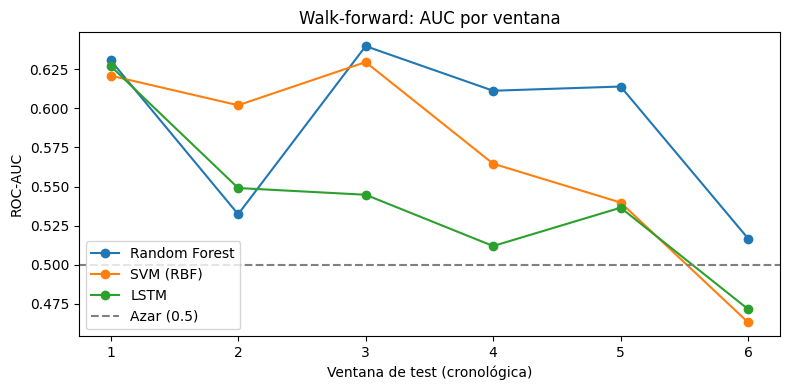

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for modelo in detalle["Modelo"].unique():
    d = detalle[detalle["Modelo"] == modelo]
    ax.plot(d["Ventana"], d["AUC"], marker="o", label=modelo)
ax.axhline(0.5, color="gray", linestyle="--", label="Azar (0.5)")
ax.set_xlabel("Ventana de test (cronológica)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Walk-forward: AUC por ventana")
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
ventanas = ventanas_walk_forward(len(df_train), 6, 120, 500, 1)
filas = []
for w, (tr_fin, te_ini, te_fin) in enumerate(ventanas, 1):
    y_te = df_train["target_venta"].values[te_ini:te_fin]
    X_te = df_train[cols_x].iloc[te_ini:te_fin]
    prev = y_te.mean()
    fila = {"Ventana": w, "Prevalencia": prev, "F1 siempre 1": 2 * prev / (1 + prev)}
    for c in ["vol_21d", "rango_intradia", "ret_1d", "dist_sma_21"]:
        fila[f"AUC {c}"] = roc_auc_score(y_te, X_te[c])
    filas.append(fila)

base = pd.DataFrame(filas).set_index("Ventana").round(3)
print(base.to_string())
print("\nPromedio:\n", base.mean().round(3).to_string())

         Prevalencia  F1 siempre 1  AUC vol_21d  AUC rango_intradia  AUC ret_1d  AUC dist_sma_21
Ventana                                                                                         
1              0.258         0.411        0.605               0.562       0.527            0.510
2              0.367         0.537        0.535               0.399       0.598            0.614
3              0.392         0.563        0.514               0.416       0.641            0.629
4              0.367         0.537        0.486               0.521       0.594            0.631
5              0.367         0.537        0.527               0.536       0.638            0.516
6              0.392         0.563        0.418               0.471       0.546            0.475

Promedio:
 Prevalencia           0.357
F1 siempre 1          0.525
AUC vol_21d           0.514
AUC rango_intradia    0.484
AUC ret_1d            0.591
AUC dist_sma_21       0.563


In [15]:
def auc_bloques_ic(y, p, bloque=10, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    n = len(y)
    nb = int(np.ceil(n / bloque))
    aucs = []
    for _ in range(n_boot):
        ini = rng.integers(0, n - bloque + 1, nb)
        idx = np.concatenate([np.arange(i, i + bloque) for i in ini])[:n]
        if len(np.unique(y[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5])


for nombre, d in acumulado.items():
    y_all = np.concatenate(d["y"])
    p_all = np.concatenate(d["p"])
    lo, hi = auc_bloques_ic(y_all, p_all)
    print(f"{nombre:<14} AUC agregado={roc_auc_score(y_all, p_all):.3f}  IC95%=[{lo:.3f}, {hi:.3f}]")

Random Forest  AUC agregado=0.582  IC95%=[0.545, 0.628]
SVM (RBF)      AUC agregado=0.558  IC95%=[0.514, 0.604]
LSTM           AUC agregado=0.540  IC95%=[0.505, 0.585]


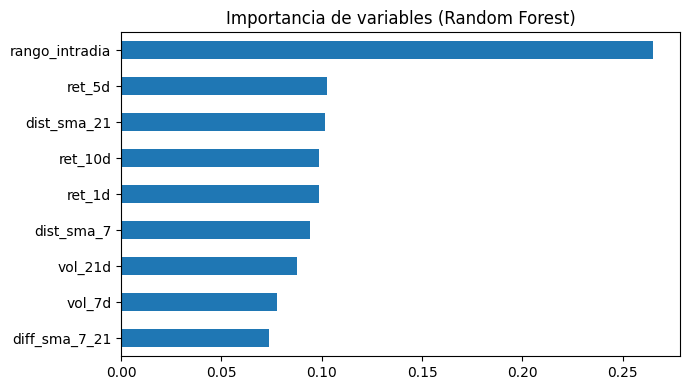

In [16]:
rf_full = RandomForestClassifier(
    n_estimators=300, max_depth=6, min_samples_leaf=10,
    class_weight="balanced", random_state=42, n_jobs=-1,
).fit(df_train[cols_x], df_train["target_venta"])

imp = pd.Series(rf_full.feature_importances_, index=cols_x).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Importancia de variables (Random Forest)")
plt.tight_layout()
plt.show()

In [17]:
def prediccion_final(df_train, ultima_fila, cols_x, seq_len=14, n_seeds=3,
                     umbral=0.5, random_state=42):
    X = df_train[cols_x]
    y = df_train["target_venta"].values.astype(int)
    n_feat = len(cols_x)
    resultados = {}

    rf = RandomForestClassifier(
        n_estimators=300, max_depth=6, min_samples_leaf=10,
        class_weight="balanced", random_state=random_state, n_jobs=-1,
    ).fit(X, y)
    resultados["Random Forest"] = rf.predict_proba(ultima_fila[cols_x])[0, 1]

    svm = make_pipeline(
        StandardScaler(),
        SVC(C=1.0, kernel="rbf", probability=True,
            class_weight="balanced", random_state=random_state),
    ).fit(X, y)
    resultados["SVM (RBF)"] = svm.predict_proba(ultima_fila[cols_x])[0, 1]

    scaler = StandardScaler().fit(X)
    X_all = scaler.transform(X).astype("float32")
    X_seq, y_seq = crear_secuencias(X_all, y, seq_len)
    X_hist = np.vstack([X_all, scaler.transform(ultima_fila[cols_x]).astype("float32")])
    sec_sig = X_hist[-seq_len:].reshape(1, seq_len, n_feat).astype("float32")
    resultados["LSTM"] = float(entrenar_lstm_ventana(
        X_seq, y_seq, sec_sig, seq_len, n_feat,
        n_seeds=n_seeds, semilla_base=random_state,
    )[0])

    print("Predicción del siguiente cierre (prob. de caída >= umbral_venta):")
    for nombre, p in resultados.items():
        print(f"  {nombre:<14} prob. clase 1 = {p:.2%} -> target_venta = {int(p >= umbral)}")
    return resultados


pred_final = prediccion_final(df_train, ultima_fila, cols_x)

Predicción del siguiente cierre (prob. de caída >= umbral_venta):
  Random Forest  prob. clase 1 = 45.37% -> target_venta = 0
  SVM (RBF)      prob. clase 1 = 30.54% -> target_venta = 0
  LSTM           prob. clase 1 = 58.54% -> target_venta = 1


In [18]:
def resumir_decision_venta(pred_dict, umbral=UMBRAL_DECISION, resumen_wf=None,
                           auc_minimo=0.55, min_ventanas=4):
    def tiene_evidencia(m):
        if resumen_wf is None or m not in resumen_wf.index:
            return False
        r = resumen_wf.loc[m]
        return (r["AUC_medio"] >= auc_minimo) and (r["Vent_AUC_mayor_0_5"] >= min_ventanas)

    print(f"=== Resumen de señal de venta (umbral >= {umbral:.0%}) ===")
    for modelo, prob in pred_dict.items():
        senal = "EVALUAR VENTA (1)" if prob >= umbral else "NO ACTIVAR VENTA (0)"
        extra = ""
        if resumen_wf is not None and modelo in resumen_wf.index:
            r = resumen_wf.loc[modelo]
            ev = "con evidencia" if tiene_evidencia(modelo) else "SIN evidencia"
            extra = (f" | AUC WF={r['AUC_medio']:.3f}, "
                     f"{int(r['Vent_AUC_mayor_0_5'])}/{int(r['N_ventanas'])} ventanas > 0.5 ({ev})")
        print(f"  - {modelo:<14}: prob={prob:.2%} -> {senal}{extra}")

    con_ev = [m for m in pred_dict if tiene_evidencia(m)]
    votos_ev = [m for m in con_ev if pred_dict[m] >= umbral]
    print(f"\nModelos con evidencia: {len(con_ev)} de {len(pred_dict)} | "
          f"de ellos, con señal de venta: {len(votos_ev)}")

    if not con_ev:
        print("Conclusión: ningún modelo es distinguible del azar; no hay señal utilizable.")
    elif not votos_ev:
        print("Conclusión: los modelos con evidencia no activan venta.")
    else:
        print(f"Conclusión: señal de venta respaldada por {', '.join(votos_ev)}.")

    print("\nNota académica: las probabilidades no están calibradas (class_weight='balanced'), "
          "el AUC de ~0.55-0.60 indica señal débil y la última vela puede ser provisional. "
          "Esta salida no constituye asesoría financiera.")


resumir_decision_venta(pred_final, resumen_wf=resumen)

=== Resumen de señal de venta (umbral >= 50%) ===
  - Random Forest : prob=45.37% -> NO ACTIVAR VENTA (0) | AUC WF=0.591, 6/6 ventanas > 0.5 (con evidencia)
  - SVM (RBF)     : prob=30.54% -> NO ACTIVAR VENTA (0) | AUC WF=0.570, 5/6 ventanas > 0.5 (con evidencia)
  - LSTM          : prob=58.54% -> EVALUAR VENTA (1) | AUC WF=0.540, 5/6 ventanas > 0.5 (SIN evidencia)

Modelos con evidencia: 2 de 3 | de ellos, con señal de venta: 0
Conclusión: los modelos con evidencia no activan venta.

Nota académica: las probabilidades no están calibradas (class_weight='balanced'), el AUC de ~0.55-0.60 indica señal débil y la última vela puede ser provisional. Esta salida no constituye asesoría financiera.


In [19]:
import pickle

# Precios de cierre (df_train no los trae); se alinean con las fechas de df_train
_cierre = yf.Ticker("USDCOP=X").history(period="10y")["Close"]
_cierre.index = pd.to_datetime(_cierre.index).tz_localize(None)
_cierre = _cierre.reindex(df_train.index)

# Predicciones fuera de muestra con su fecha (reconstruye las ventanas del walk-forward)
_n_vent = int(resumen["N_ventanas"].iloc[0])
_ventanas = ventanas_walk_forward(len(df_train), _n_vent, 120, 500, 1)
_filas = []
for _nombre, _d in acumulado.items():
    for _w, (_tr, _ti, _tf) in enumerate(_ventanas):
        _filas.append(pd.DataFrame({
            "fecha": df_train.index[_ti:_tf], "modelo": _nombre,
            "prob": _d["p"][_w], "y": _d["y"][_w], "ventana": _w + 1}))
_preds = pd.concat(_filas, ignore_index=True)

# Intervalo de confianza del AUC agregado (usa auc_bloques_ic, ya definida en tu notebook)
_ic = []
for _nombre, _d in acumulado.items():
    _y, _p = np.concatenate(_d["y"]), np.concatenate(_d["p"])
    _lo, _hi = auc_bloques_ic(_y, _p)
    _ic.append({"Modelo": _nombre, "AUC agregado": round(roc_auc_score(_y, _p), 3),
                "IC95% inf": round(_lo, 3), "IC95% sup": round(_hi, 3)})
_ic = pd.DataFrame(_ic).set_index("Modelo")

with open("resultados_app.pkl", "wb") as f:
    pickle.dump(dict(resumen=resumen, detalle=detalle, preds=_preds, pred_final=pred_final,
                     imp=imp, ic=_ic, close=_cierre, ultima_fila=ultima_fila,
                     df_train=df_train, tabla_final=tabla_final), f)
print("Listo: resultados_app.pkl guardado")

Listo: resultados_app.pkl guardado


In [20]:
%%writefile app.py
import pickle
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import streamlit as st

st.set_page_config(page_title="USD/COP · Señal de venta", page_icon="📉", layout="wide")

@st.cache_data
def cargar():
    with open("resultados_app.pkl", "rb") as f:
        return pickle.load(f)

R = cargar()
resumen, detalle, preds = R["resumen"], R["detalle"], R["preds"]
pred_final, imp, ic = R["pred_final"], R["imp"], R["ic"]
close, ultima, train = R["close"], R["ultima_fila"], R["df_train"]
AUC_MIN, MIN_VENT = 0.55, 4

def evidencia(m):
    r = resumen.loc[m]
    return r["AUC_medio"] >= AUC_MIN and r["Vent_AUC_mayor_0_5"] >= MIN_VENT

st.title("📉 USD/COP · Señal de venta con IA")
st.caption("Resultados del Parcial 3 (Random Forest, SVM y LSTM). Proyecto académico: no es asesoría financiera.")

umbral = st.sidebar.slider("Umbral de decisión (prob.)", 0.30, 0.80, 0.50, 0.01)
st.sidebar.caption(f"Datos: {train.index.min().date()} → {train.index.max().date()}")

c1, c2, c3, c4 = st.columns(4)
c1.metric("Último cierre", f"${float(ultima['Close'].iloc[0]):,.0f} COP",
          f"{float(ultima['ret_1d'].iloc[0]):+.2%} vs día previo")
c2.metric("Fecha del dato", str(ultima.index[0].date()))
c3.metric("Filas de entrenamiento", f"{len(train):,}")
c4.metric("Prevalencia de caída", f"{train['target_venta'].mean():.1%}")

t1, t2, t3, t4, t5 = st.tabs(["🎯 Señal actual", "📈 Precio y señales", "🔁 Walk-forward",
                              "🧪 Split único", "🧩 Variables"])

with t1:
    st.subheader("Predicción para el siguiente cierre")
    cols = st.columns(len(pred_final))
    for col, (m, p) in zip(cols, pred_final.items()):
        with col, st.container(border=True):
            st.markdown(f"**{m}**")
            st.metric("Prob. de caída", f"{p:.1%}")
            st.write("🔴 **Evaluar venta**" if p >= umbral else "🟢 No activar venta")
            st.caption("✅ Con evidencia de señal" if evidencia(m) else "⚠️ Sin evidencia de señal")
    con_ev = [m for m in pred_final if evidencia(m)]
    votos = [m for m in con_ev if pred_final[m] >= umbral]
    if not con_ev:
        st.warning("Ningún modelo es distinguible del azar.")
    elif not votos:
        st.success(f"Los modelos con evidencia ({', '.join(con_ev)}) no activan venta.")
    else:
        st.error(f"Señal de venta respaldada por: {', '.join(votos)}.")
    st.caption(f"Evidencia = AUC medio ≥ {AUC_MIN} y AUC > 0.5 en al menos {MIN_VENT} ventanas. "
               "Las probabilidades no están calibradas (class_weight='balanced').")

with t2:
    modelo = st.selectbox("Modelo", list(resumen.index),
                          index=list(resumen.index).index("Random Forest"))
    p = preds[preds["modelo"] == modelo].set_index("fecha")
    sen = p[p["prob"] >= umbral].index
    real = p[p["y"] == 1].index
    c = close[close.index >= p.index.min()]
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=c.index, y=c.values, mode="lines", name="Cierre USD/COP"))
    fig.add_trace(go.Scatter(x=real, y=close.reindex(real), mode="markers", name="Caída real (t+1)",
                             marker=dict(symbol="triangle-down", size=7, color="#2a9d8f", opacity=.7)))
    fig.add_trace(go.Scatter(x=sen, y=close.reindex(sen), mode="markers", name=f"Señal ({modelo})",
                             marker=dict(symbol="circle-open", size=9, color="#e63946")))
    fig.update_layout(height=450, hovermode="x unified", margin=dict(l=10, r=10, t=30, b=10),
                      legend=dict(orientation="h", y=1.08), yaxis_title="COP por USD")
    st.plotly_chart(fig, width="stretch")
    n = len(sen)
    acierto = p.loc[sen, "y"].mean() if n else np.nan
    prev = p["y"].mean()
    k1, k2, k3, k4 = st.columns(4)
    k1.metric("Días evaluados", len(p))
    k2.metric("Señales de venta", n)
    k3.metric("Acierto al señalar", "—" if n == 0 else f"{acierto:.1%}")
    k4.metric("Referencia (prevalencia)", f"{prev:.1%}",
              None if n == 0 else f"{(acierto - prev) * 100:+.1f} pp")
    st.caption("Solo predicciones fuera de muestra (walk-forward).")

with t3:
    st.subheader("Resumen por modelo")
    st.dataframe(resumen, width="stretch")
    fig2 = go.Figure()
    for m in detalle["Modelo"].unique():
        d = detalle[detalle["Modelo"] == m]
        fig2.add_trace(go.Scatter(x=d["Ventana"], y=d["AUC"], mode="lines+markers", name=m))
    fig2.add_hline(y=0.5, line_dash="dash", line_color="gray", annotation_text="Azar")
    fig2.update_layout(height=350, xaxis_title="Ventana", yaxis_title="ROC-AUC",
                       margin=dict(l=10, r=10, t=20, b=10))
    st.plotly_chart(fig2, width="stretch")
    st.subheader("AUC agregado con intervalo de confianza (bloques)")
    st.dataframe(ic, width="stretch")
    with st.expander("Detalle por ventana"):
        st.dataframe(detalle.round(3), width="stretch", hide_index=True)

with t4:
    st.subheader("Evaluación con un solo corte train/test (3 años)")
    st.dataframe(R["tabla_final"], width="stretch")
    st.caption("Un único test de ~150 días es un solo régimen de mercado; por eso se añadió el walk-forward.")

with t5:
    st.subheader("Importancia de variables (Random Forest)")
    fig3 = go.Figure(go.Bar(x=imp.values, y=imp.index, orientation="h"))
    fig3.update_layout(height=380, margin=dict(l=10, r=10, t=20, b=10))
    st.plotly_chart(fig3, width="stretch")
    st.subheader("Última fila usada para predecir")
    st.dataframe(ultima.round(5), width="stretch")

Writing app.py


In [21]:
!pip install -q streamlit plotly
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared

import subprocess, time, re
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)
tunel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                         stderr=subprocess.PIPE, text=True)
for linea in tunel.stderr:
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", linea)
    if m:
        print("Abre esta URL en otra pestaña:", m.group(0))
        break

Abre esta URL en otra pestaña: https://stage-healthy-hired-hebrew.trycloudflare.com
